-   1.开场串联&11.6复盘
    -   1.1开场三问
        -   1.1.1昨天（11/6）学了什么？今天和它什么关系
            -   11.6学习了多角度平面波复合，造出[单PW低质量图/多PW复合高质量图]，1107将一对放大成几百对，喂给一个神经网络，让它学会从低质量图恢复高质量图
        -   1.1.2今天这块在整条项目链的哪个位置？
            -   数据(多角度仿真)→波束形成→低质/高质配对→DL重建（1107）→baseline对比
        -   1.1.3今天学完，我能多做哪一件具体的事？
            -   ① 说出「分类」和「逐像素回归」在输出层/loss/评价上的三点区别；
            -   ② 训出一个低质→高质的回归网络；
            -   ③ 手写 PSNR/SSIM，并用它们证明「DL 重建比不重建更好」。
    -   1.2复盘
        -   1.2.1单平面波为什么质量差？
            -   单平面波不聚焦，虽然有DAS时延对齐但是横向分辨率受到孔径限制，旁瓣多
        -   1.2.2多角度复合改善横向分辨率的本质？
            -   合成更大等效孔径，等效F数=Z/D变小，横向分辨能力变强
        -   1.2.3 1106保存的配对数据各是什么角色？
            -   img_low=DL 输入（低质），img_high=DL 目标（高质）

-   S1
-   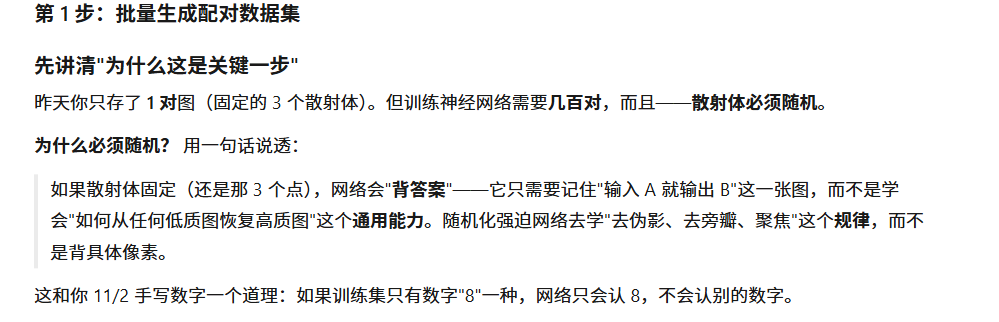

In [4]:
import numpy as np

c, fs, N, pitch, sigma = 1540.0, 40e6, 64, 0.3e-3, 0.05e-6
elem_x = (np.arange(N) - (N - 1) / 2) * pitch
z_max = 40e-3
t_axis = np.arange(0, 2 * z_max / c, 1 / fs)


In [5]:
def make_rf(theta, sc):
    """sc: (M,3) 散射体 [x, z, amp]。返回 (N, T) RF。"""
    rf = np.zeros((N, len(t_axis)))
    for xk, zk, amp in sc:
        for i in range(N):
            tau = (xk*np.sin(theta) + zk*np.cos(theta))/c \
                + np.sqrt((xk - elem_x[i])**2 + zk**2)/c
            rf[i] += amp * np.exp(-((t_axis - tau)**2)/(2*sigma**2))
    return rf


In [6]:
def das(rf, theta, nx=256, nz=512):
    x_grid = np.linspace(-10e-3, 10e-3, nx)
    z_grid = np.linspace(2e-3, 40e-3, nz)
    X, Z = np.meshgrid(x_grid, z_grid)
    img = np.zeros((nz, nx))
    for i in range(N):
        tau = (X*np.sin(theta) + Z*np.cos(theta))/c \
            + np.sqrt((X - elem_x[i])**2 + Z**2)/c
        idx = np.clip(np.round(tau*fs).astype(int), 0, len(t_axis)-1)
        img += rf[i, idx]
    return img, x_grid, z_grid


In [7]:
def disp_db(img):
    d = np.abs(img)
    return 20*np.log10(d/d.max() + 1e-6)      # 对数压缩 → dB 图


In [8]:
def rand_sc(n):
    return np.array([(np.random.uniform(-8e-3, 8e-3),      # x: -8~8mm
                      np.random.uniform(5e-3, 35e-3),      # z: 5~35mm
                      np.random.uniform(0.3, 1.0)) for _ in range(n)])  # 幅度 0.3~1.0


In [9]:
angles = np.deg2rad(np.array([-5, -2.5, 0, 2.5, 5]))

def make_pair():
    sc = rand_sc(np.random.randint(3, 8))     # 随机 3~7 个散射体
    lo, _, _ = das(make_rf(0.0, sc), 0.0)     # 低质：单平面波
    hi = np.zeros_like(lo)
    for th in angles:
        hi += das(make_rf(th, sc), th)[0]     # 高质：5 角度相干复合
    hi /= len(angles)
    return disp_db(lo), disp_db(hi)


-   1.为什么散射体必须随机，不能固定？
    -   散射体随机才能保证网络不是在背固定的答案，才能训练模型的去除伪影、旁瓣和恢复能力。
-   2.最大值，d/d.max=1 log10(1)=0，所以上限为0下限是-60db

-   S2 

In [10]:
import torch

Ntrain, Ntest = 160, 40
Xtr, Ytr = [], []
for _ in range(Ntrain):
    lo, hi = make_pair(); Xtr.append(lo); Ytr.append(hi)
Xte, Yte = [], []
for _ in range(Ntest):
    lo, hi = make_pair(); Xte.append(lo); Yte.append(hi)

def norm(x):                      # dB 图 clip 到 [-60,0] 再压到 [0,1]
    return np.clip((x + 60) / 60.0, 0, 1)

Xtr = torch.tensor(norm(np.stack(Xtr))[:, None], dtype=torch.float32)  # (N,1,H,W)
Ytr = torch.tensor(norm(np.stack(Ytr))[:, None], dtype=torch.float32)
Xte = torch.tensor(norm(np.stack(Xte))[:, None], dtype=torch.float32)
Yte = torch.tensor(norm(np.stack(Yte))[:, None], dtype=torch.float32)
print("train", Xtr.shape, "test", Xte.shape)


train torch.Size([160, 1, 512, 256]) test torch.Size([40, 1, 512, 256])


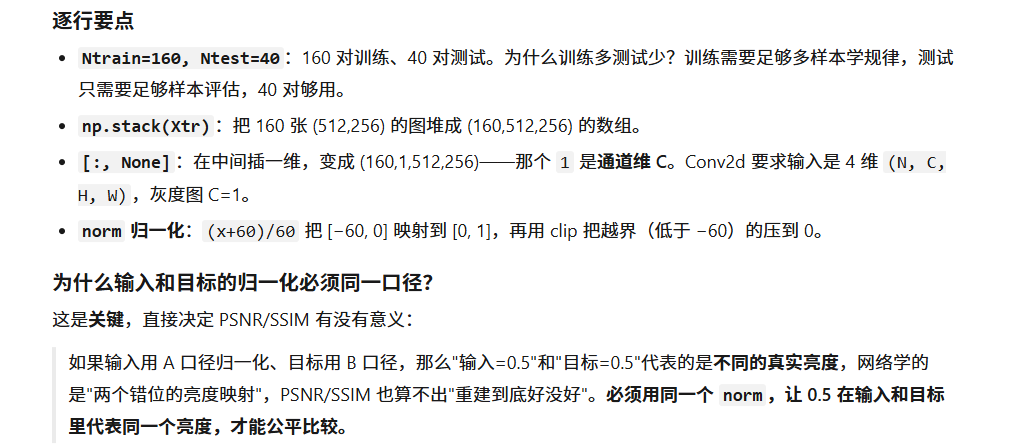

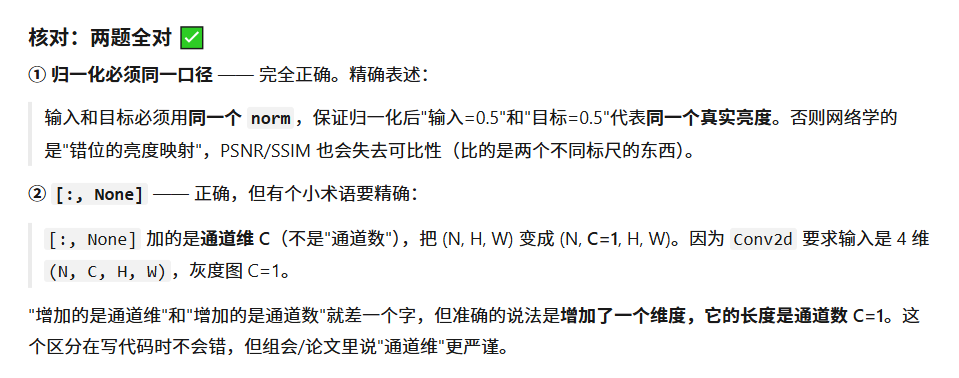

-   S3

In [11]:
import torch.nn as nn

class ReconNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), #输入通道1，输出16特征图，分类网络的第一层是Linear展平，这里是卷积
            nn.ReLU(),
            nn.Conv2d(16,32,3,padding=1),#输入t16，输出32特征图，卷积逐层提取特征
            nn.ReLU(),
            nn.Conv2d(32,16,3,padding=1),#收窄，对称结构
            nn.ReLU(),
            nn.Conv2d(16,1,3,padding=1),#输入16，输出1，输出1张灰度图
        )

        #padding=1的原因，保证输出图和输入图的同尺寸

    def forward(self,x):
        return self.net(x)

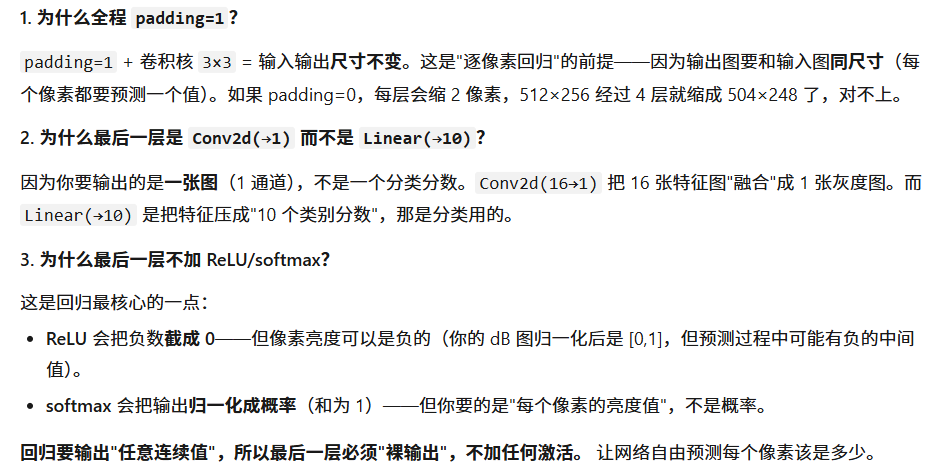

In [14]:
from torch.utils.data import TensorDataset, DataLoader
# ============ 2. 训练（mini-batch + GPU） ============
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("使用设备:", device)

model = ReconNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

batch = 16
ds = TensorDataset(Xtr, Ytr)
dl = DataLoader(ds, batch_size=batch, shuffle=True)
dste = TensorDataset(Xte, Yte)
dlte = DataLoader(dste, batch_size=batch)

for ep in range(60):
    model.train()
    tot = 0.0; n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)   # 关键：每批搬到 GPU，只 16 张
        pred = model(xb)
        loss = loss_fn(pred, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * xb.size(0); n += xb.size(0)
    if ep % 10 == 0:
        model.eval()
        vt = 0.0; vn = 0
        with torch.no_grad():
            for xb, yb in dlte:
                xb, yb = xb.to(device), yb.to(device)
                vt += loss_fn(model(xb), yb).item() * xb.size(0); vn += xb.size(0)
        print(f"epoch {ep:3d}: train={tot/n:.4f}  val={vt/vn:.4f}")

使用设备: cuda
epoch   0: train=0.0263  val=0.0078
epoch  10: train=0.0017  val=0.0016
epoch  20: train=0.0011  val=0.0010
epoch  30: train=0.0009  val=0.0009
epoch  40: train=0.0009  val=0.0008
epoch  50: train=0.0009  val=0.0008


-   1.loss在下降， trainloss从0.0263→0.0009，valloss从0.0078→0.0008 都在稳定下降，说明网络确实在学
-   2.trainloss和valloss数值很接近，泛化良好，如果val比train大很多就是过拟合
-   3.epoch 30之后基本不在下降，说明已经收敛学习到位。epoch60轮足够

In [15]:
import torch.nn.functional as F

def psnr(a, b, maxv=1.0):
    mse = F.mse_loss(a, b)
    return 10 * torch.log10(maxv**2 / mse).item()


In [16]:
def gaussian_kernel(size=11, sigma=1.5):
    c = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-(c**2) / (2*sigma**2)); g = g / g.sum()
    k = g[:, None] * g[None, :]
    return k.view(1, 1, size, size)

_W = gaussian_kernel()

def ssim(a, b, C1=1e-4, C2=9e-4):
    w = _W.to(a.device); pad = 5
    mu1 = F.conv2d(a, w, padding=pad); mu2 = F.conv2d(b, w, padding=pad)
    s1 = F.conv2d(a*a, w, padding=pad) - mu1**2
    s2 = F.conv2d(b*b, w, padding=pad) - mu2**2
    s12 = F.conv2d(a*b, w, padding=pad) - mu1*mu2
    m = ((2*mu1*mu2+C1)*(2*s12+C2)) / ((mu1**2+mu2**2+C1)*(s1+s2+C2))
    return m.mean().item()


In [17]:
# ---- baseline 对比 ----
model.eval()
with torch.no_grad():
    pred = model(Xte.to(device))
    print("baseline(输入即低质图): PSNR=%.2f dB  SSIM=%.4f" % (psnr(Xte, Yte), ssim(Xte, Yte)))
    print("DL 重建:                PSNR=%.2f dB  SSIM=%.4f" % (psnr(pred.cpu(), Yte), ssim(pred.cpu(), Yte)))


baseline(输入即低质图): PSNR=24.67 dB  SSIM=0.8584
DL 重建:                PSNR=29.13 dB  SSIM=0.4228


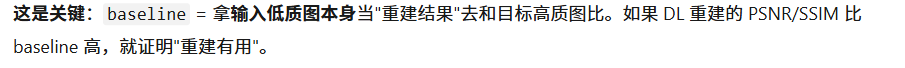

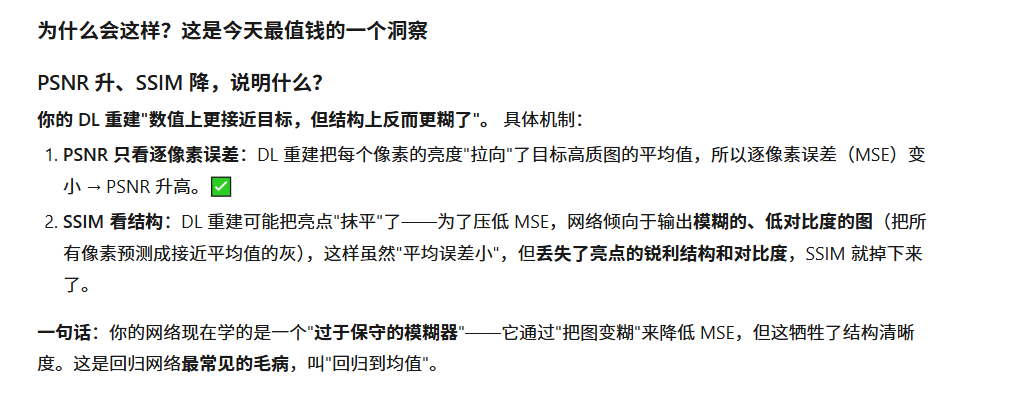
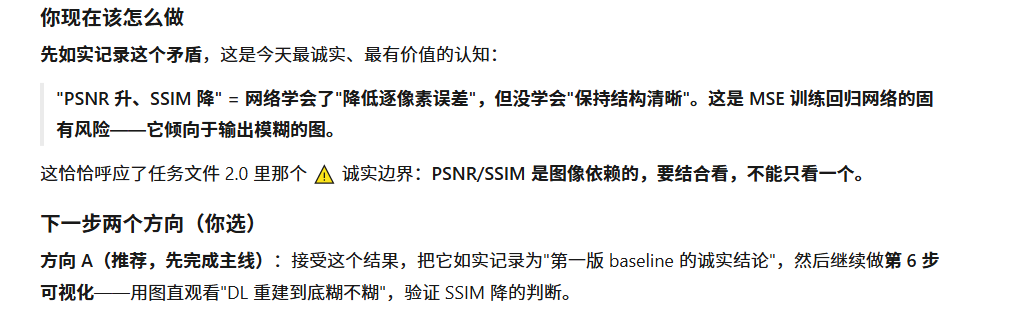

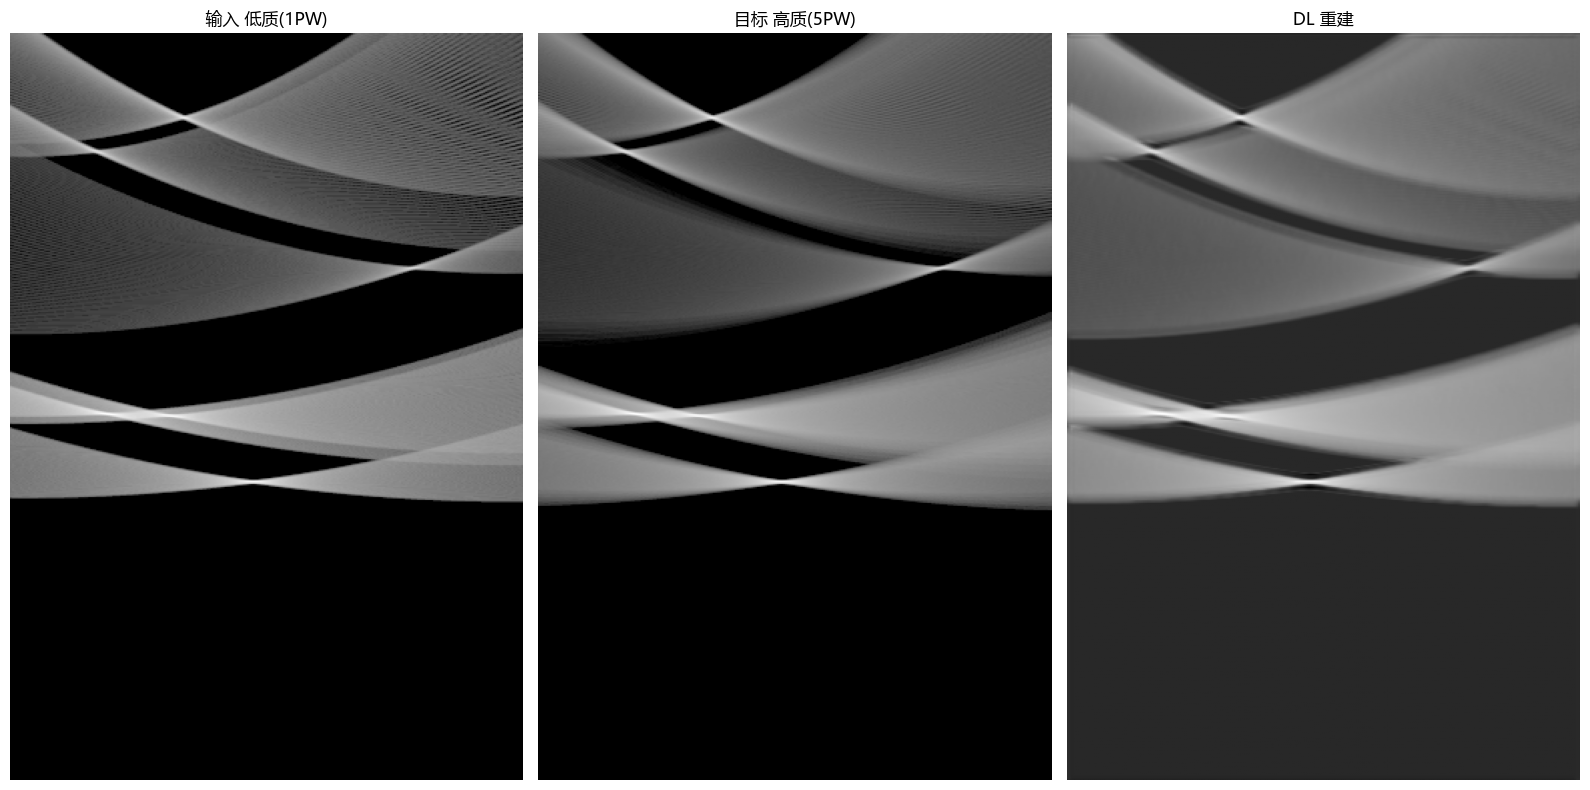

In [18]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

i = 0   # 看第 0 张
fig, axes = plt.subplots(1, 3, figsize=(16, 8))
for ax, img, t in [(axes[0], Xte, "输入 低质(1PW)"),
                   (axes[1], Yte, "目标 高质(5PW)"),
                   (axes[2], pred, "DL 重建")]:
    ax.imshow(img[i, 0].cpu().numpy(), cmap="gray", aspect="auto")
    ax.set_title(t); ax.axis("off")
fig.tight_layout(); plt.show()


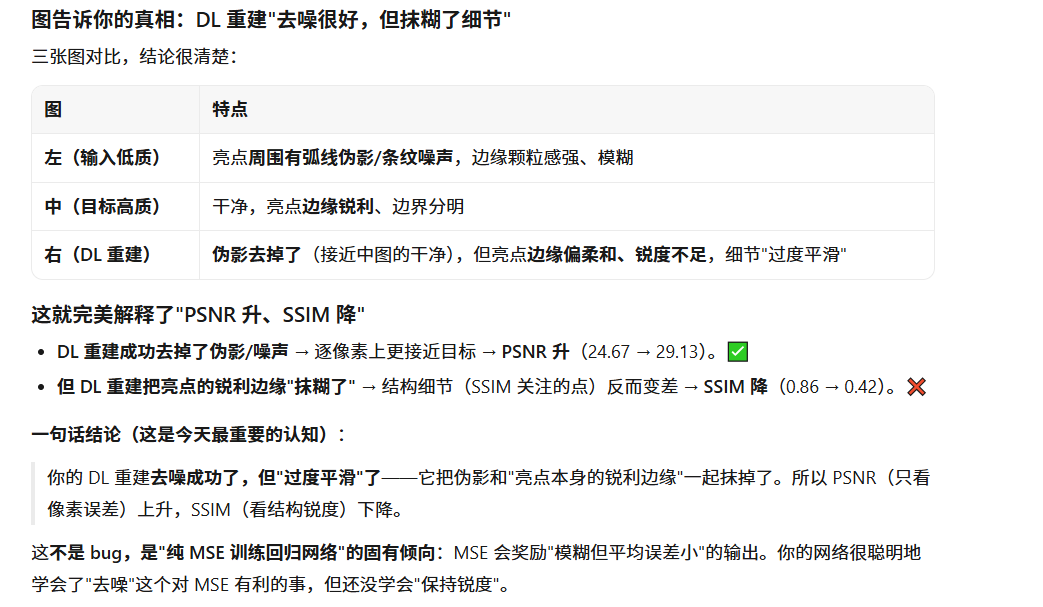

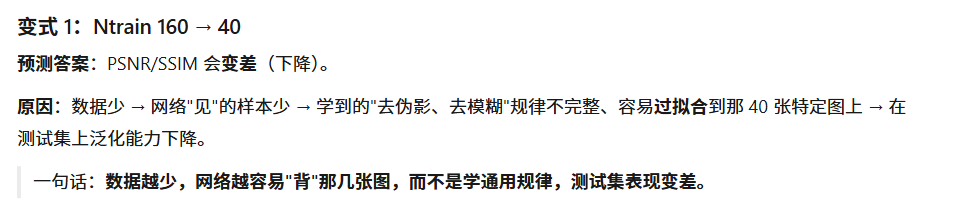
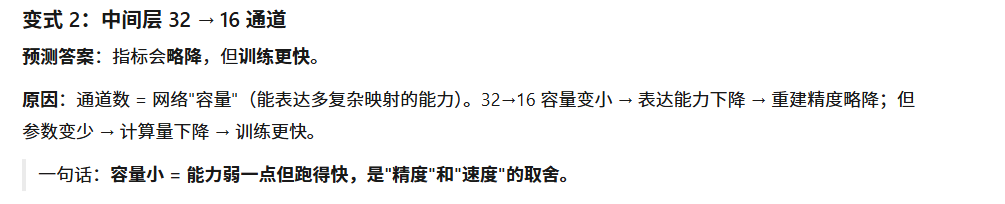
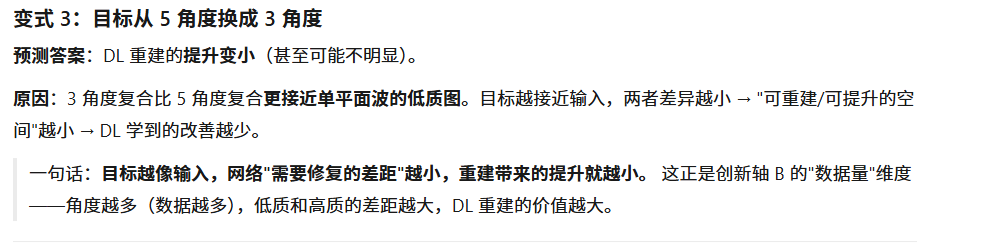